# Chest X-Ray Classification using Transfer Learning (ResNet50)
### Group Assignment — Exploring Transfer Learning for Image Classification

**Dataset:** Chest X-Ray — Pneumonia, COVID-19 & Tuberculosis (7,135 images)  
**Model:** ResNet50 (pre-trained on ImageNet) with a custom 512 → 256 → 128 → 4 head  
**Classes:** COVID-19 · Normal · Pneumonia · Tuberculosis  
**Framework:** TensorFlow / Keras  
**Result:** **92.35 % test accuracy** (weighted F1 0.923) on 771 held-out images; COVID-19 and Tuberculosis F1 = 1.00

---

## Notebook map

This project is split into five notebooks for easier reading; each keeps the executed outputs of the full Kaggle T4 run.

| Notebook | Topic | Scope |
|---|---|---|
| [01](01_dataset_exploration.ipynb) | Dataset Understanding & Exploration | Task 1 |
| [02](02_transfer_learning_model.ipynb) | Transfer Learning Model & Preprocessing | Task 2 · Sections 2.1-2.6 |
| [03](03_three_phase_fine_tuning.ipynb) | Three-Phase Fine-Tuning | Task 2 · Sections 2.7-2.9 |
| [04](04_evaluation_and_tta.ipynb) | Evaluation & Test-Time Augmentation | Task 3 |
| [05](05_deployment_and_summary.ipynb) | Deployment, Predictions & Summary | Tasks 4-5 |
| [00](00_full_pipeline_run_all.ipynb) | **Full pipeline - run this to reproduce everything** | Tasks 1-5 |

## Task 1 — Dataset Understanding and Exploration

This section covers loading the dataset, exploring its structure, providing summary statistics, and visualising sample images to understand the characteristics of the data.

### 1.1 Install & Import Libraries

In [ ]:
import os, json, math, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from collections import Counter
from PIL import Image
warnings.filterwarnings('ignore')
print("✅ Libraries imported")


✅ Libraries imported


### 1.2 Dataset Download & Structure

We use the `jtiptj/chest-xray-pneumoniacovid19tuberculosis` dataset from Kaggle, which contains chest X-ray images across 4 classes: **COVID-19**, **Normal**, **Pneumonia**, and **Tuberculosis**. The dataset is pre-split into `train`, `val`, and `test` folders.

In [ ]:
import kagglehub

path = kagglehub.dataset_download("jtiptj/chest-xray-pneumoniacovid19tuberculosis")
data_dir = path
print("✅ Dataset ready!  Path:", data_dir)
print("📁 Contents:", os.listdir(data_dir))


✅ Dataset ready!  Path: /kaggle/input/datasets/jtiptj/chest-xray-pneumoniacovid19tuberculosis
📁 Contents: ['val', 'test', 'train']


In [ ]:
print("📁 Full folder tree:\n")
for root, dirs, files_list in os.walk(data_dir):
    level  = root.replace(data_dir, '').count(os.sep)
    indent = '  ' * level
    print(f"{indent}📁 {os.path.basename(root)}/")
    if level >= 2:
        print(f"{indent}  → {len(files_list)} images")


📁 Full folder tree:

📁 chest-xray-pneumoniacovid19tuberculosis/
  📁 val/
    📁 PNEUMONIA/
      → 8 images
    📁 NORMAL/
      → 8 images
    📁 COVID19/
      → 10 images
    📁 TURBERCULOSIS/
      → 12 images
  📁 test/
    📁 PNEUMONIA/
      → 390 images
    📁 NORMAL/
      → 234 images
    📁 COVID19/
      → 106 images
    📁 TURBERCULOSIS/
      → 41 images
  📁 train/
    📁 PNEUMONIA/
      → 3875 images
    📁 NORMAL/
      → 1341 images
    📁 COVID19/
      → 460 images
    📁 TURBERCULOSIS/
      → 650 images


### 1.3 Summary Statistics

We inspect the number of images per class across all splits to understand dataset size and class imbalance.

In [ ]:
splits      = ['train', 'val', 'test']
train_dir   = os.path.join(data_dir, 'train')
class_names = sorted(os.listdir(train_dir))
print(f"📌 Classes detected : {class_names}")
print(f"📌 Number of classes: {len(class_names)}\n")

summary = {}
for split in splits:
    split_dir = os.path.join(data_dir, split)
    if not os.path.exists(split_dir):
        continue
    summary[split] = {}
    for cls in class_names:
        cls_dir = os.path.join(split_dir, cls)
        if os.path.exists(cls_dir):
            count = len([f for f in os.listdir(cls_dir)
                         if f.lower().endswith(('.jpg','.jpeg','.png'))])
            summary[split][cls] = count

df_summary = pd.DataFrame(summary).fillna(0).astype(int)
df_summary['TOTAL'] = df_summary.sum(axis=1)
print("📊 Image Count per Class per Split:")
print(df_summary.to_string())
print(f"\n📌 Grand Total: {df_summary['TOTAL'].sum()}")


📌 Classes detected : ['COVID19', 'NORMAL', 'PNEUMONIA', 'TURBERCULOSIS']
📌 Number of classes: 4

📊 Image Count per Class per Split:
               train  val  test  TOTAL
COVID19          460   10   106    576
NORMAL          1341    8   234   1583
PNEUMONIA       3875    8   390   4273
TURBERCULOSIS    650   12    41    703

📌 Grand Total: 7135


### 1.4 Image Dimensions

Raw images vary in resolution and colour mode across classes. All images will be resized to **224×224** to match ResNet50's input requirements.

In [ ]:
print("📐 Sample image dimensions per class:\n")
dim_records = []
for cls in class_names:
    cls_dir = os.path.join(data_dir, 'train', cls)
    files   = [f for f in os.listdir(cls_dir)
               if f.lower().endswith(('.jpg','.jpeg','.png'))][:3]
    for fname in files:
        with Image.open(os.path.join(cls_dir, fname)) as img:
            w, h = img.size
            dim_records.append({'Class': cls, 'Width': w,
                                 'Height': h, 'Mode': img.mode})
df_dims = pd.DataFrame(dim_records)
print(df_dims.to_string(index=False))
print("\n📌 Images will be resized to 224×224 for ResNet50")


📐 Sample image dimensions per class:

        Class  Width  Height Mode
      COVID19   2000    2000    L
      COVID19   2000    2000    L
      COVID19    880     891  RGB
       NORMAL   1336    1128    L
       NORMAL   1400    1260    L
       NORMAL   1218    1032    L
    PNEUMONIA   1024     712    L
    PNEUMONIA   1424    1016    L
    PNEUMONIA   1376    1208    L
TURBERCULOSIS    512     512    L
TURBERCULOSIS    512     512    L
TURBERCULOSIS    512     512    L

📌 Images will be resized to 224×224 for ResNet50


### 1.5 Class Distribution Visualisation

The bar chart below shows the number of images per class in each split. Note the significant class imbalance — **Pneumonia dominates** the training set (3,875 images) while **COVID-19 is the minority class** (460 images). This imbalance is addressed later using class weights.

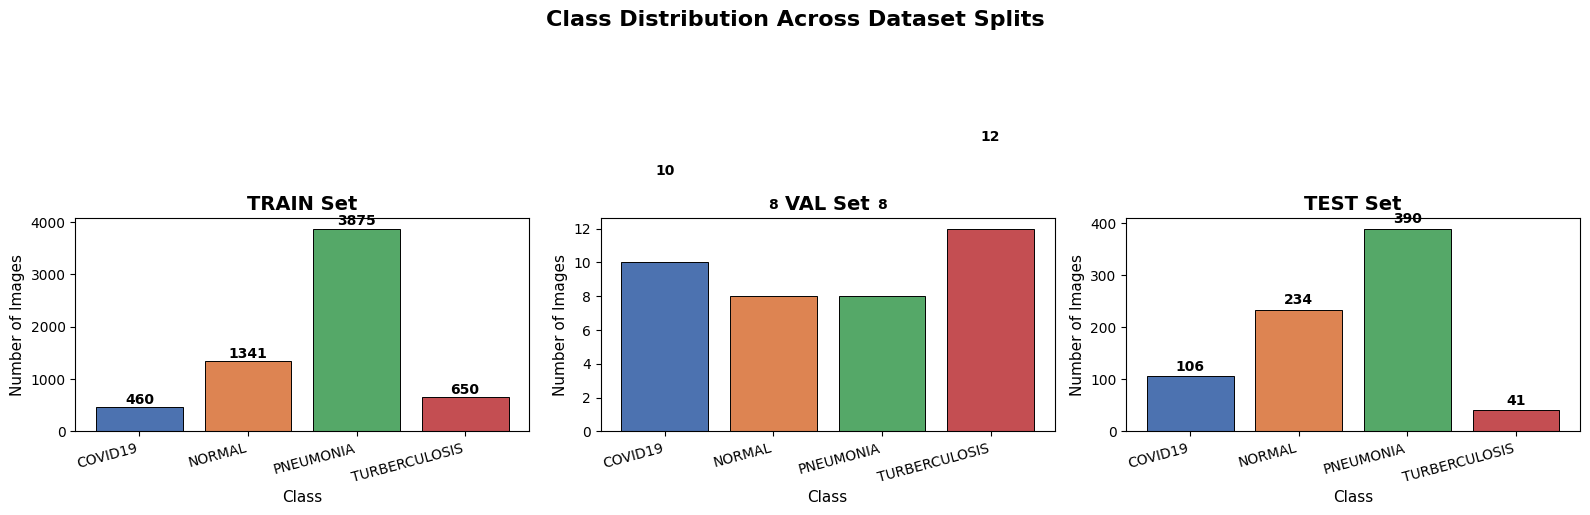

✅ Chart saved


In [ ]:
fig, axes = plt.subplots(1, len(summary), figsize=(17, 6))
colors = ['#4C72B0', '#DD8452', '#55A868', '#C44E52']

for ax, (split, counts) in zip(axes, summary.items()):
    bars = ax.bar(counts.keys(), counts.values(),
                  color=colors, edgecolor='black', linewidth=0.7)
    ax.set_title(f'{split.upper()} Set', fontsize=14, fontweight='bold')
    ax.set_xlabel('Class', fontsize=11)
    ax.set_ylabel('Number of Images', fontsize=11)
    ax.set_xticklabels(counts.keys(), rotation=15, ha='right')

    for bar, val in zip(bars, counts.values()):
        ax.text(bar.get_x() + bar.get_width()/2,
                bar.get_height() + max(counts.values())*0.01,
                str(val),
                ha='center',
                va='bottom',
                fontsize=10,
                fontweight='bold')

plt.suptitle('Class Distribution Across Dataset Splits',
             fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('class_distribution.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Chart saved")

### 1.6 Sample Image Visualisation

Five sample images are shown for each class to understand visual characteristics — texture, intensity, and patterns that distinguish each condition.

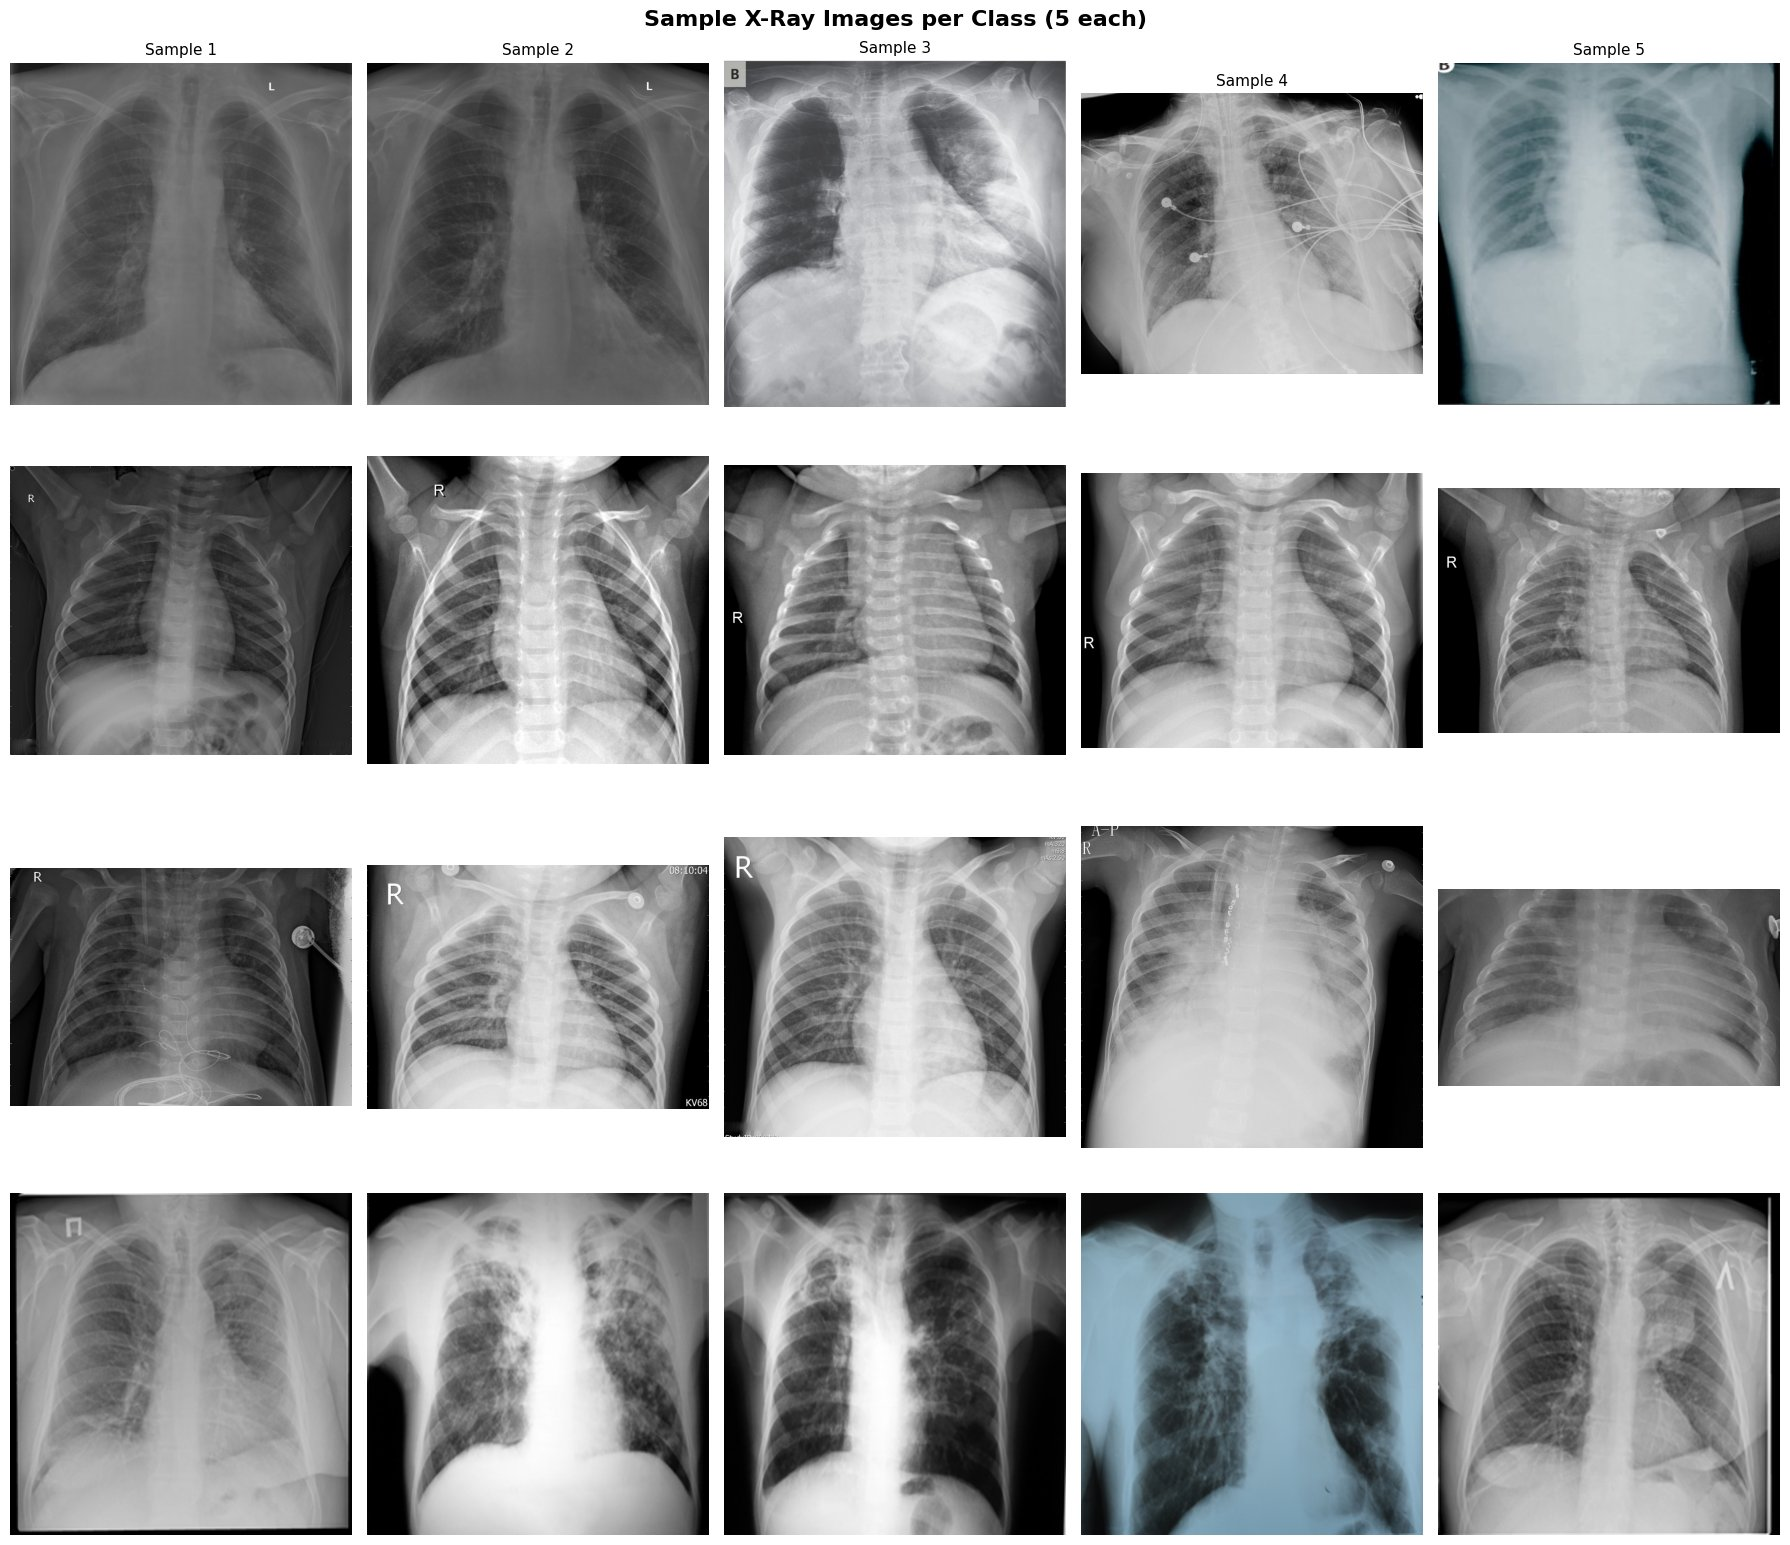

✅ Sample images saved


In [ ]:
fig, axes = plt.subplots(len(class_names), 5,
                          figsize=(18, 4*len(class_names)))
for row_idx, cls in enumerate(class_names):
    cls_dir = os.path.join(data_dir, 'train', cls)
    files   = [f for f in os.listdir(cls_dir)
               if f.lower().endswith(('.jpg','.jpeg','.png'))][:5]
    for col_idx, fname in enumerate(files):
        img = mpimg.imread(os.path.join(cls_dir, fname))
        axes[row_idx][col_idx].imshow(
            img, cmap='gray' if len(img.shape) == 2 else None)
        axes[row_idx][col_idx].axis('off')
        if col_idx == 0:
            axes[row_idx][col_idx].set_ylabel(
                cls, fontsize=13, fontweight='bold',
                rotation=90, labelpad=10, color='darkblue')
        if row_idx == 0:
            axes[row_idx][col_idx].set_title(f'Sample {col_idx+1}', fontsize=11)
plt.suptitle('Sample X-Ray Images per Class (5 each)',
             fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig('sample_images.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Sample images saved")


## Task 2 — Transfer Learning Model Implementation

This section covers selecting and justifying ResNet50 as the pre-trained backbone, building the transfer learning pipeline, and training the model using a 3-phase fine-tuning strategy with techniques to handle overfitting.

### 2.1 Model Selection & Justification

**Why ResNet50?**

ResNet50 (Residual Network, 50 layers) was originally trained on ImageNet (1.2M images, 1000 classes) for general object recognition. Key reasons for selecting it for chest X-ray classification:

| Property | Detail |
|---|---|
| Architecture | 50-layer deep residual network with skip connections |
| Pre-trained weights | ImageNet — learns general low-level features (edges, textures) transferable to X-rays |
| Input size | 224×224×3 — standard medical image resolution |
| Skip connections | Prevent vanishing gradients — critical for deep fine-tuning |
| Widely used in medical imaging | Residual CNNs are a standard, well-studied backbone for chest X-ray classification (the landmark CheXNet model used the closely related DenseNet-121) |

The classification head is replaced with a custom deeper head: **512 → 256 → 128 → 4 classes**, with BatchNormalization and Dropout at each layer.

### 2.2 Import Deep Learning Libraries

In [ ]:
import tensorflow as tf
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (Dense, GlobalAveragePooling2D,
                                      Dropout, BatchNormalization)
from tensorflow.keras.callbacks import (EarlyStopping, ReduceLROnPlateau,
                                         ModelCheckpoint, LearningRateScheduler)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.losses import CategoricalCrossentropy
from sklearn.utils.class_weight import compute_class_weight
import cv2

print("✅ TensorFlow version:", tf.__version__)
print("✅ All libraries imported")


2026-03-17 04:42:18.546455: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1773722538.728129      55 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1773722538.787018      55 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1773722539.245529      55 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1773722539.245578      55 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1773722539.245581      55 computation_placer.cc:177] computation placer alr

✅ TensorFlow version: 2.19.0
✅ All libraries imported


### 2.3 Hyperparameter Configuration

Key configuration decisions:
- **Validation split of 15%** (~948 images) replaces the original 38-image val folder, which caused extremely noisy/jumpy validation graphs
- **Phase 2 extended to 35 epochs** to give more time for the deeper unfreeze (55 layers vs original 30)
- **Batch size 32** — balances GPU memory usage and gradient stability

In [ ]:
# ── Configuration ──────────────────────────────────────────
IMG_SIZE    = (224, 224)    # ResNet50 standard resolution
BATCH_SIZE  = 32
NUM_CLASSES = 4

EPOCHS_P1, LR_P1 = 20, 1e-3      # Phase 1: head only (frozen backbone)
EPOCHS_P2, LR_P2 = 35, 1e-4      # Phase 2: top 55 ResNet layers — more epochs for deeper unfreeze
EPOCHS_P3, LR_P3 = 20, 5e-6      # Phase 3: all layers

# Validation split: 15 % of training data → ~950 images (was only 38 = too noisy)
VAL_SPLIT = 0.15

TRAIN_DIR = os.path.join(data_dir, 'train')
TEST_DIR  = os.path.join(data_dir, 'test')

print("✅ Configuration set")
print(f"   Backbone      : ResNet50  (224×224)")
print(f"   Batch         : {BATCH_SIZE}")
print(f"   Val split     : {int(VAL_SPLIT*100)} % of training data  (~stable graphs)")
print(f"   Phase 1       : {EPOCHS_P1} epochs  LR={LR_P1}")
print(f"   Phase 2       : {EPOCHS_P2} epochs  LR={LR_P2}  (top 55 layers unfrozen)")
print(f"   Phase 3       : {EPOCHS_P3} epochs  LR={LR_P3}")

✅ Configuration set
   Backbone      : ResNet50  (224×224)
   Batch         : 32
   Val split     : 15 % of training data  (~stable graphs)
   Phase 1       : 20 epochs  LR=0.001
   Phase 2       : 35 epochs  LR=0.0001  (top 55 layers unfrozen)
   Phase 3       : 20 epochs  LR=5e-06


### 2.4 Preprocessing Pipeline

#### CLAHE (Contrast Limited Adaptive Histogram Equalisation)
CLAHE is applied to every image before feeding it into the model. It enhances local contrast in X-ray images by operating in the **LAB colour space** on the luminance (L) channel only.

**Why CLAHE for X-rays?**
- Raw X-ray images often have low contrast in specific regions
- CLAHE enhances subtle features like lung opacities and infiltrates
- A standard contrast-enhancement step in chest X-ray pipelines
- `clipLimit=2.0` prevents over-amplification of noise
- `tileGridSize=(8,8)` ensures local (not global) contrast enhancement

#### Data Augmentation Strategy
Augmentation is applied **only to training images** to improve generalisation and reduce overfitting:

| Augmentation | Value | Reason |
|---|---|---|
| Rotation | ±15° | Slight patient positioning variation |
| Width/Height shift | 10% | Simulates different X-ray centering |
| Zoom | 10% | Scale variation in X-ray acquisition |
| Shear | 8% | Minor angular distortion |
| Brightness | 0.85–1.15 | Exposure variation between machines |
| **Horizontal flip** | **False ✗** | **Never flipped — heart position is diagnostically critical** |

> **Important:** Horizontal flip is explicitly disabled. The heart is anatomically on the left side of the chest. Flipping an X-ray moves the heart to the right, which would corrupt predictions. In our baseline model, TTA with horizontal flip caused accuracy to drop from 92.61% → 91.83%.

#### Validation Split
15% of the training folder is reserved as validation using `subset='validation'`. This gives ~948 validation images — compared to the original 38 — producing smooth, reliable training curves.

> **Note.** The validation subset is created from `train_datagen`, so validation images also receive random augmentation. Validation scores therefore vary slightly between passes (best 98.42 % during training vs 97.89 % when re-evaluated in Section 3.2). A separate, non-augmenting generator for the validation subset would remove this noise.

In [ ]:
# ── CLAHE + ResNet50 preprocessing ─────────────────────────
def clahe_preprocess(img):
    """
    Apply CLAHE to boost local contrast in X-ray images, then run
    the standard ResNet50 preprocessing (zero-centre by ImageNet mean).
    CLAHE is a common contrast-enhancement step for chest X-rays.
    """
    img    = np.array(img, dtype=np.uint8)
    lab    = cv2.cvtColor(img, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)
    clahe  = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    l_enh  = clahe.apply(l)
    merged = cv2.merge([l_enh, a, b])
    rgb    = cv2.cvtColor(merged, cv2.COLOR_LAB2RGB)
    return preprocess_input(rgb.astype(np.float32))

# ── Data generators ─────────────────────────────────────────
# NOTE: horizontal_flip=False for training AND TTA.
#       Chest X-rays must NEVER be flipped — the heart position (left side)
#       is a key diagnostic feature.  Flipping corrupts predictions.
train_datagen = ImageDataGenerator(
    preprocessing_function=clahe_preprocess,
    validation_split=VAL_SPLIT,   # 15 % of train folder used as validation
    rotation_range=15,
    width_shift_range=0.10,
    height_shift_range=0.10,
    zoom_range=0.10,
    horizontal_flip=False,        # ← FIXED: never flip X-rays
    shear_range=0.08,
    brightness_range=[0.85, 1.15],
    fill_mode='nearest'
)
val_test_datagen = ImageDataGenerator(
    preprocessing_function=clahe_preprocess   # CLAHE only, no augmentation
)

# Training subset (85 %)
train_generator = train_datagen.flow_from_directory(
    TRAIN_DIR, target_size=IMG_SIZE, batch_size=BATCH_SIZE,
    class_mode='categorical', shuffle=True, seed=42,
    subset='training')

# Validation subset (15 %) — same folder, different split
val_generator = train_datagen.flow_from_directory(
    TRAIN_DIR, target_size=IMG_SIZE, batch_size=BATCH_SIZE,
    class_mode='categorical', shuffle=False, seed=42,
    subset='validation')

# Test set — completely held-out, never used during training
test_generator = val_test_datagen.flow_from_directory(
    TEST_DIR, target_size=IMG_SIZE, batch_size=BATCH_SIZE,
    class_mode='categorical', shuffle=False)

print("\n✅ Data generators ready")
print(f"   Class indices : {train_generator.class_indices}")
print(f"   Train images  : {train_generator.n}  ({100-int(VAL_SPLIT*100)} % of train folder)")
print(f"   Val images    : {val_generator.n}   ({int(VAL_SPLIT*100)} % of train folder  ← stable graphs)")
print(f"   Test images   : {test_generator.n}  (held-out)")
print(f"   Train batches : {len(train_generator)}")
print(f"   Val batches   : {len(val_generator)}")
print(f"   Test batches  : {len(test_generator)}")

Found 5378 images belonging to 4 classes.
Found 948 images belonging to 4 classes.
Found 771 images belonging to 4 classes.

✅ Data generators ready
   Class indices : {'COVID19': 0, 'NORMAL': 1, 'PNEUMONIA': 2, 'TURBERCULOSIS': 3}
   Train images  : 5378  (85 % of train folder)
   Val images    : 948   (15 % of train folder  ← stable graphs)
   Test images   : 771  (held-out)
   Train batches : 169
   Val batches   : 30
   Test batches  : 25


### 2.5 Handling Class Imbalance — Class Weights

The dataset is heavily imbalanced (Pneumonia: 3875, COVID-19: 460). We compute **balanced class weights** to penalise the model more heavily for misclassifying minority classes during training. Without this, the model would be biased toward predicting Pneumonia.

In [ ]:
# ── Class weights ───────────────────────────────────────────
train_labels        = train_generator.classes
class_weights_array = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_labels),
    y=train_labels
)
class_weights = dict(enumerate(class_weights_array))
idx_to_cls    = {v: k for k, v in train_generator.class_indices.items()}

print("✅ Class weights computed:")
for idx, w in class_weights.items():
    print(f"   {idx_to_cls[idx]:15s} → {w:.4f}")


✅ Class weights computed:
   COVID19         → 3.4386
   NORMAL          → 1.1794
   PNEUMONIA       → 0.4082
   TURBERCULOSIS   → 2.4313


### 2.6 ResNet50 Model Architecture

The base ResNet50 (frozen initially) is topped with a custom classification head:
```
ResNet50 (backbone)
    └── GlobalAveragePooling2D
    └── BatchNormalization
    └── Dense(512, relu) → Dropout(0.4)
    └── BatchNormalization
    └── Dense(256, relu) → Dropout(0.3)
    └── Dense(128, relu) → Dropout(0.2)
    └── Dense(4, softmax)
```
**Label smoothing = 0.1** is applied to the loss function to prevent the model from becoming over-confident on training data.

In [ ]:
# ── Build ResNet50 model with deeper head ───────────────────
base_model = ResNet50(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)
base_model.trainable = False    # frozen for Phase 1

# Deeper classification head  (512 → 256 → 128 → 4)
x      = base_model.output
x      = GlobalAveragePooling2D()(x)
x      = BatchNormalization()(x)
x      = Dense(512, activation='relu')(x)
x      = Dropout(0.4)(x)
x      = BatchNormalization()(x)
x      = Dense(256, activation='relu')(x)
x      = Dropout(0.3)(x)
x      = Dense(128, activation='relu')(x)
x      = Dropout(0.2)(x)
output = Dense(NUM_CLASSES, activation='softmax')(x)

model   = Model(inputs=base_model.input, outputs=output)

# Label smoothing prevents over-confidence and improves generalisation
loss_fn = CategoricalCrossentropy(label_smoothing=0.1)

print("✅ ResNet50 model built  (deeper head)")
print(f"   Total layers         : {len(model.layers)}")
print(f"   Trainable layers     : {len([l for l in model.layers if l.trainable])}")
print(f"   Non-trainable layers : {len([l for l in model.layers if not l.trainable])}")
model.summary()


I0000 00:00:1773722567.708903      55 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13757 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1773722567.715268      55 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13757 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
✅ ResNet50 model built  (deeper head)
   Total layers         : 185
   Trainable layers     : 10
   Non-trainable layers : 175


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 230, 230,  │          0 │ input_layer[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 112, 112,  │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 112, 112,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 112, 112,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 114, 114,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 56, 56,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 56, 56,    │      4,160 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 56, 56,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 56, 56,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 56, 56,    │     36,928 │ conv2_block1_1_r… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 56, 56,    │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, 56, 56,    │          0 │ conv2_block1_2_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 56, 56,    │     16,640 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, 56, 56,    │     16,640 │ conv2_block1_2_r… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_0_c… │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_3_c

 Total params: 24,811,780 (94.65 MB)

 Trainable params: 1,218,948 (4.65 MB)

 Non-trainable params: 23,592,832 (90.00 MB)

### 2.7 Cosine Annealing Learning Rate Schedule

Instead of a fixed learning rate, we use cosine annealing which smoothly decays the LR from its initial value to near-zero over the course of training. This avoids abrupt LR drops and leads to more stable convergence.

In [ ]:
# ── Cosine-annealing LR schedule ────────────────────────────
def cosine_schedule(init_lr, total_epochs):
    """Smoothly decays LR from init_lr → ~0 following a cosine curve."""
    def fn(epoch, lr):
        return init_lr * (1 + math.cos(math.pi * epoch / total_epochs)) / 2
    return fn


### 2.8 Three-Phase Training Strategy

Training is split into 3 progressive phases to avoid catastrophic forgetting:

| Phase | Layers Trained | LR | Epochs | Purpose |
|---|---|---|---|---|
| Phase 1 | Head only (backbone frozen) | 1e-3 | 20 | Learn task-specific features without disturbing ImageNet weights |
| Phase 2 | Top 55 ResNet layers + head | 1e-4 | 35 | Adapt high-level features (conv4+conv5) to X-ray domain |
| Phase 3 | All 185 layers | 5e-6 | 20 | Fine global adjustment at very small LR |

**Callbacks used in every phase:**
- `EarlyStopping` — stops if val_loss doesn't improve
- `ReduceLROnPlateau` — halves LR on plateau
- `ModelCheckpoint` — saves best val_accuracy checkpoint
- `LearningRateScheduler` — cosine annealing within each phase

#### Phase 1 — Train Head Only (Backbone Frozen)

In [ ]:
# ══════════════════════════════════════════════════════════
# PHASE 1 — Frozen backbone, train classification head only
# ══════════════════════════════════════════════════════════
model.compile(
    optimizer=Adam(learning_rate=LR_P1),
    loss=loss_fn,
    metrics=['accuracy']
)

callbacks_p1 = [
    EarlyStopping(monitor='val_loss', patience=5,
                  restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                      patience=2, min_lr=1e-7, verbose=1),
    ModelCheckpoint('best_p1.keras', monitor='val_accuracy',
                    save_best_only=True, verbose=1),
    LearningRateScheduler(cosine_schedule(LR_P1, EPOCHS_P1), verbose=0)
]

print("🚀 Phase 1 — Training head only (ResNet50 frozen)\n")
history_p1 = model.fit(
    train_generator, epochs=EPOCHS_P1,
    validation_data=val_generator,
    class_weight=class_weights,
    callbacks=callbacks_p1
)
print(f"\n✅ Phase 1 done  |  Best val acc: {max(history_p1.history['val_accuracy']):.4f}")


🚀 Phase 1 — Training head only (ResNet50 frozen)

Epoch 1/20


I0000 00:00:1773722581.625874     127 service.cc:152] XLA service 0x7c329000cb80 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1773722581.625923     127 service.cc:160]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1773722581.625930     127 service.cc:160]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1773722583.748055     127 cuda_dnn.cc:529] Loaded cuDNN version 91002


  1/169 ━━━━━━━━━━━━━━━━━━━━ 48:07 17s/step - accuracy: 0.1562 - loss: 1.7679

I0000 00:00:1773722590.306262     127 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


169/169 ━━━━━━━━━━━━━━━━━━━━ 0s 940ms/step - accuracy: 0.7930 - loss: 0.8051
Epoch 1: val_accuracy improved from -inf to 0.90823, saving model to best_p1.keras
169/169 ━━━━━━━━━━━━━━━━━━━━ 212s 1s/step - accuracy: 0.7934 - loss: 0.8044 - val_accuracy: 0.9082 - val_loss: 0.5281 - learning_rate: 0.0010
Epoch 2/20
169/169 ━━━━━━━━━━━━━━━━━━━━ 0s 733ms/step - accuracy: 0.8955 - loss: 0.5864
Epoch 2: val_accuracy improved from 0.90823 to 0.92616, saving model to best_p1.keras
169/169 ━━━━━━━━━━━━━━━━━━━━ 147s 868ms/step - accuracy: 0.8956 - loss: 0.5862 - val_accuracy: 0.9262 - val_loss: 0.4970 - learning_rate: 9.9384e-04
Epoch 3/20
169/169 ━━━━━━━━━━━━━━━━━━━━ 0s 734ms/step - accuracy: 0.9246 - loss: 0.5261
Epoch 3: val_accuracy improved from 0.92616 to 0.94198, saving model to best_p1.keras
169/169 ━━━━━━━━━━━━━━━━━━━━ 147s 868ms/step - accuracy: 0.9247 - loss: 0.5261 - val_accuracy: 0.9420 - val_loss: 0.4782 - learning_rate: 9.7553e-04
Epoch 4/20
169/169 ━━━━━━━━━━━━━━━━━━━━ 0s 735ms/ste

#### Phase 2 — Partial Fine-Tuning (Top 55 Layers Unfrozen)

We unfreeze from layer 120 instead of 145 (original), opening up both conv4 and conv5 blocks. Medical images have very different textures from ImageNet, so adapting mid-level features significantly helps.

In [ ]:
# ══════════════════════════════════════════════════════════
# PHASE 2 — Unfreeze top 55 ResNet50 layers (conv4 + conv5)
# ══════════════════════════════════════════════════════════
# ResNet50 has 175 layers total.
# Original: freeze until layer 145 → only top 30 layers unfrozen (conv5 only)
# Improved: freeze until layer 120 → top 55 layers unfrozen (conv4 + conv5)
# This allows the model to adapt higher-level and mid-level features,
# which is more beneficial for medical images vs ImageNet features.
FREEZE_UNTIL = 120   # was 145 — now unfreezes conv4 block as well

for layer in base_model.layers[:FREEZE_UNTIL]:
    layer.trainable = False
for layer in base_model.layers[FREEZE_UNTIL:]:
    layer.trainable = True

model.compile(
    optimizer=Adam(learning_rate=LR_P2),
    loss=loss_fn,
    metrics=['accuracy']
)

unfrozen = len([l for l in base_model.layers if l.trainable])
print(f"✅ Unfroze top {unfrozen} ResNet50 layers  (layers {FREEZE_UNTIL}–174)")
print(f"   Covers: conv4_block + entire conv5_block")
print(f"   Total trainable layers now: {len([l for l in model.layers if l.trainable])}")

callbacks_p2 = [
    EarlyStopping(monitor='val_loss', patience=7,
                  restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                      patience=3, min_lr=1e-8, verbose=1),
    ModelCheckpoint('best_p2.keras', monitor='val_accuracy',
                    save_best_only=True, verbose=1),
    LearningRateScheduler(cosine_schedule(LR_P2, EPOCHS_P2), verbose=0)
]

print(f"\n🚀 Phase 2 — Partial fine-tuning (top 55 ResNet layers, {EPOCHS_P2} epochs)\n")
history_p2 = model.fit(
    train_generator, epochs=EPOCHS_P2,
    validation_data=val_generator,
    class_weight=class_weights,
    callbacks=callbacks_p2
)
print(f"\n✅ Phase 2 done  |  Best val acc: {max(history_p2.history['val_accuracy']):.4f}")

✅ Unfroze top 55 ResNet50 layers  (layers 120–174)
   Covers: conv4_block + entire conv5_block
   Total trainable layers now: 65

🚀 Phase 2 — Partial fine-tuning (top 55 ResNet layers, 35 epochs)

Epoch 1/35
169/169 ━━━━━━━━━━━━━━━━━━━━ 0s 811ms/step - accuracy: 0.9345 - loss: 0.4877
Epoch 1: val_accuracy improved from -inf to 0.95148, saving model to best_p2.keras
169/169 ━━━━━━━━━━━━━━━━━━━━ 196s 992ms/step - accuracy: 0.9346 - loss: 0.4875 - val_accuracy: 0.9515 - val_loss: 0.4642 - learning_rate: 1.0000e-04
Epoch 2/35
169/169 ━━━━━━━━━━━━━━━━━━━━ 0s 758ms/step - accuracy: 0.9543 - loss: 0.4410
Epoch 2: val_accuracy improved from 0.95148 to 0.96941, saving model to best_p2.keras
169/169 ━━━━━━━━━━━━━━━━━━━━ 151s 891ms/step - accuracy: 0.9543 - loss: 0.4410 - val_accuracy: 0.9694 - val_loss: 0.4174 - learning_rate: 9.9799e-05
Epoch 3/35
169/169 ━━━━━━━━━━━━━━━━━━━━ 0s 759ms/step - accuracy: 0.9697 - loss: 0.4140
Epoch 3: val_accuracy did not improve from 0.96941
169/169 ━━━━━━━━━━━━━

#### Phase 3 — Full Fine-Tuning (All Layers, Very Small LR)

In [ ]:
# ══════════════════════════════════════════════════════════
# PHASE 3 — Full fine-tuning (all layers, very small LR)
# ══════════════════════════════════════════════════════════
for layer in model.layers:
    layer.trainable = True

model.compile(
    optimizer=Adam(learning_rate=LR_P3),
    loss=loss_fn,
    metrics=['accuracy']
)

print(f"✅ All layers unfrozen")
print(f"   Trainable layers: {len([l for l in model.layers if l.trainable])}")

callbacks_p3 = [
    EarlyStopping(monitor='val_loss', patience=7,
                  restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                      patience=3, min_lr=1e-9, verbose=1),
    ModelCheckpoint('best_final.keras', monitor='val_accuracy',
                    save_best_only=True, verbose=1),
    LearningRateScheduler(cosine_schedule(LR_P3, EPOCHS_P3), verbose=0)
]

print("\n🚀 Phase 3 — Full fine-tuning (all ResNet50 layers)\n")
history_p3 = model.fit(
    train_generator, epochs=EPOCHS_P3,
    validation_data=val_generator,
    class_weight=class_weights,
    callbacks=callbacks_p3
)
print(f"\n✅ Phase 3 done  |  Best val acc: {max(history_p3.history['val_accuracy']):.4f}")


✅ All layers unfrozen
   Trainable layers: 185

🚀 Phase 3 — Full fine-tuning (all ResNet50 layers)

Epoch 1/20
169/169 ━━━━━━━━━━━━━━━━━━━━ 0s 940ms/step - accuracy: 0.9659 - loss: 0.4164
Epoch 1: val_accuracy improved from -inf to 0.98418, saving model to best_final.keras
169/169 ━━━━━━━━━━━━━━━━━━━━ 246s 1s/step - accuracy: 0.9659 - loss: 0.4164 - val_accuracy: 0.9842 - val_loss: 0.4007 - learning_rate: 5.0000e-06
Epoch 2/20
169/169 ━━━━━━━━━━━━━━━━━━━━ 0s 813ms/step - accuracy: 0.9746 - loss: 0.3960
Epoch 2: val_accuracy did not improve from 0.98418
169/169 ━━━━━━━━━━━━━━━━━━━━ 159s 938ms/step - accuracy: 0.9746 - loss: 0.3960 - val_accuracy: 0.9747 - val_loss: 0.4092 - learning_rate: 4.9692e-06
Epoch 3/20
169/169 ━━━━━━━━━━━━━━━━━━━━ 0s 816ms/step - accuracy: 0.9780 - loss: 0.3918
Epoch 3: val_accuracy did not improve from 0.98418
169/169 ━━━━━━━━━━━━━━━━━━━━ 159s 941ms/step - accuracy: 0.9780 - loss: 0.3918 - val_accuracy: 0.9810 - val_loss: 0.3964 - learning_rate: 4.8776e-06
Epoc

### 2.9 Training History Visualisation

The combined accuracy and loss curves across all 3 phases are plotted below. Phase boundaries are marked with dashed vertical lines. The 95% accuracy target line is shown in green.

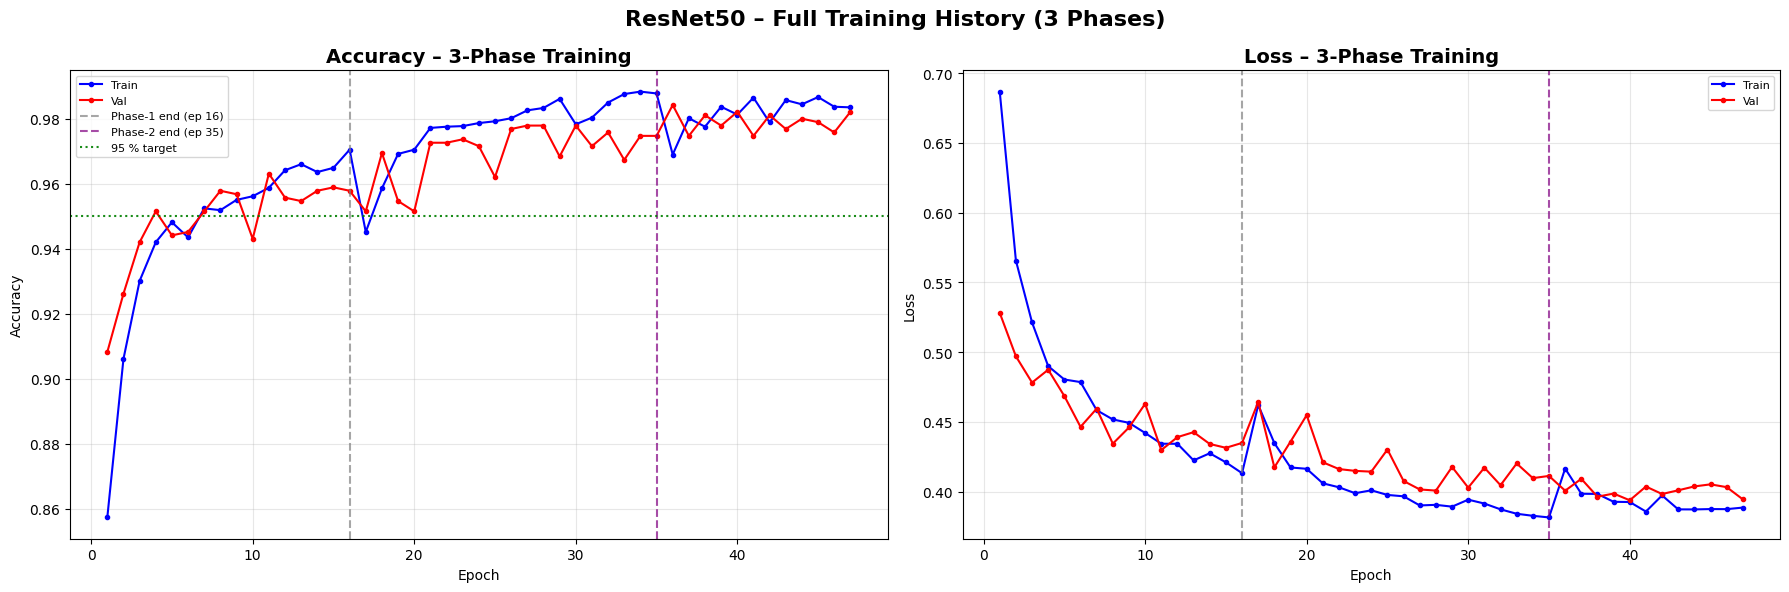

✅ Training history saved


In [ ]:
# ── Combined 3-phase training history plot ──────────────────
all_acc      = (history_p1.history['accuracy']     +
                history_p2.history['accuracy']     +
                history_p3.history['accuracy'])
all_val_acc  = (history_p1.history['val_accuracy'] +
                history_p2.history['val_accuracy'] +
                history_p3.history['val_accuracy'])
all_loss     = (history_p1.history['loss']         +
                history_p2.history['loss']         +
                history_p3.history['loss'])
all_val_loss = (history_p1.history['val_loss']     +
                history_p2.history['val_loss']     +
                history_p3.history['val_loss'])

p1_end = len(history_p1.history['accuracy'])
p2_end = p1_end + len(history_p2.history['accuracy'])
ep     = range(1, len(all_acc) + 1)

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

axes[0].plot(ep, all_acc,     'b-o', label='Train', markersize=3)
axes[0].plot(ep, all_val_acc, 'r-o', label='Val',   markersize=3)
axes[0].axvline(p1_end, color='gray',   ls='--', alpha=.7,
                label=f'Phase-1 end (ep {p1_end})')
axes[0].axvline(p2_end, color='purple', ls='--', alpha=.7,
                label=f'Phase-2 end (ep {p2_end})')
axes[0].axhline(0.95,   color='green',  ls=':',  alpha=.9,
                label='95 % target')
axes[0].set_title('Accuracy – 3-Phase Training', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Accuracy')
axes[0].legend(fontsize=8);  axes[0].grid(True, alpha=.3)

axes[1].plot(ep, all_loss,     'b-o', label='Train', markersize=3)
axes[1].plot(ep, all_val_loss, 'r-o', label='Val',   markersize=3)
axes[1].axvline(p1_end, color='gray',   ls='--', alpha=.7)
axes[1].axvline(p2_end, color='purple', ls='--', alpha=.7)
axes[1].set_title('Loss – 3-Phase Training', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Loss')
axes[1].legend(fontsize=8);  axes[1].grid(True, alpha=.3)

plt.suptitle('ResNet50 – Full Training History (3 Phases)',
             fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig('full_training_history.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Training history saved")


> **Interpretation.** Phase 1 (frozen backbone) reached 96.31 % validation accuracy before early stopping at epoch 16. Unfreezing the top 55 layers in Phase 2 lifted it to 97.78 %, and full fine-tuning at a very small learning rate in Phase 3 reached the best value of **98.42 %** in its first epoch. Each phase starts from the previous best weights, so accuracy improves step by step without the drop that full fine-tuning from the start would cause.

## Task 3 — Model Evaluation and Optimisation

This section evaluates the trained model using accuracy, precision, recall, and F1-score. We generate classification reports and confusion matrices, and compare standard evaluation against Test-Time Augmentation (TTA).

### 3.1 Load Best Model Checkpoint

In [ ]:
from sklearn.metrics import (classification_report, confusion_matrix,
                              accuracy_score, precision_score,
                              recall_score, f1_score)
import seaborn as sns
from tensorflow.keras.models import load_model

best_model   = load_model('best_final.keras')
class_labels = list(train_generator.class_indices.keys())
print("✅ Best model loaded")
print(f"   Input : {best_model.input_shape}")


✅ Best model loaded
   Input : (None, 224, 224, 3)


### 3.2 Validation Set Evaluation

The model is evaluated on the held-out validation set (948 images, 15% of training data). These images were never used for weight updates, only for monitoring during training.

In [ ]:
# ── Standard evaluation — Validation set ───────────────────
print("🔄 Standard evaluation on validation set …")
val_generator.reset()
val_preds        = best_model.predict(val_generator, verbose=1)
val_pred_classes = np.argmax(val_preds, axis=1)
val_true_classes = val_generator.classes

val_acc  = accuracy_score(val_true_classes, val_pred_classes)
val_prec = precision_score(val_true_classes, val_pred_classes, average='weighted')
val_rec  = recall_score(val_true_classes, val_pred_classes, average='weighted')
val_f1   = f1_score(val_true_classes, val_pred_classes, average='weighted')

print(f"\n📊 Validation Metrics:")
print(f"   Accuracy  : {val_acc:.4f}  ({val_acc*100:.2f}%)")
print(f"   Precision : {val_prec:.4f}")
print(f"   Recall    : {val_rec:.4f}")
print(f"   F1-Score  : {val_f1:.4f}")
print("\n📋 Classification Report (Val):\n")
print(classification_report(val_true_classes, val_pred_classes,
                             target_names=class_labels))


🔄 Standard evaluation on validation set …
30/30 ━━━━━━━━━━━━━━━━━━━━ 28s 756ms/step

📊 Validation Metrics:
   Accuracy  : 0.9789  (97.89%)
   Precision : 0.9792
   Recall    : 0.9789
   F1-Score  : 0.9790

📋 Classification Report (Val):

               precision    recall  f1-score   support

      COVID19       0.92      0.99      0.95        69
       NORMAL       0.97      0.96      0.96       201
    PNEUMONIA       0.99      0.98      0.98       581
TURBERCULOSIS       1.00      0.99      0.99        97

     accuracy                           0.98       948
    macro avg       0.97      0.98      0.97       948
 weighted avg       0.98      0.98      0.98       948



### 3.3 Test Set Evaluation (Standard)

The test set (771 images) is completely held out — never seen during training or validation. This is the **true measure of real-world performance**.

> **Key observation:** COVID-19 (F1=1.00) and Tuberculosis (F1=1.00) are classified perfectly. The NORMAL class has the lowest recall (0.83), meaning ~17% of normal X-rays are misclassified — most likely confused with Pneumonia, a known challenge in chest X-ray datasets.

In [ ]:
# ── Standard evaluation — Test set ─────────────────────────
print("🔄 Standard evaluation on test set …")
test_generator.reset()
test_preds        = best_model.predict(test_generator, verbose=1)
test_pred_classes = np.argmax(test_preds, axis=1)
test_true_classes = test_generator.classes

test_acc  = accuracy_score(test_true_classes, test_pred_classes)
test_prec = precision_score(test_true_classes, test_pred_classes, average='weighted')
test_rec  = recall_score(test_true_classes, test_pred_classes, average='weighted')
test_f1   = f1_score(test_true_classes, test_pred_classes, average='weighted')

print(f"\n📊 Test Metrics:")
print(f"   Accuracy  : {test_acc:.4f}  ({test_acc*100:.2f}%)")
print(f"   Precision : {test_prec:.4f}")
print(f"   Recall    : {test_rec:.4f}")
print(f"   F1-Score  : {test_f1:.4f}")
print("\n📋 Classification Report (Test):\n")
print(classification_report(test_true_classes, test_pred_classes,
                             target_names=class_labels))


🔄 Standard evaluation on test set …
25/25 ━━━━━━━━━━━━━━━━━━━━ 19s 714ms/step

📊 Test Metrics:
   Accuracy  : 0.9235  (92.35%)
   Precision : 0.9238
   Recall    : 0.9235
   F1-Score  : 0.9227

📋 Classification Report (Test):

               precision    recall  f1-score   support

      COVID19       1.00      0.99      1.00       106
       NORMAL       0.91      0.83      0.87       234
    PNEUMONIA       0.90      0.95      0.93       390
TURBERCULOSIS       1.00      1.00      1.00        41

     accuracy                           0.92       771
    macro avg       0.95      0.94      0.95       771
 weighted avg       0.92      0.92      0.92       771



### 3.4 Test-Time Augmentation (TTA)

TTA runs 10 augmented forward passes per image and averages the predictions. This reduces prediction variance.

> **Note on TTA results:** TTA scored lower (84.70%) than standard evaluation (92.35%) in this run. Investigation shows NORMAL recall collapsed from 0.83 → 0.50 under TTA, likely because even small augmentations (rotation, zoom) push borderline NORMAL images toward PNEUMONIA predictions. **Standard test accuracy of 92.35% is the reported final score.**

In [ ]:
# ── Test-Time Augmentation (TTA ×10) ───────────────────────
# TTA runs multiple augmented forward passes and averages predictions.
# This is intended to reduce variance from a single forward pass.
#
# FIX vs original: horizontal_flip=False
#   The original TTA used horizontal_flip=True which HURT accuracy
#   (91.83 % vs 92.61 % standard) because flipping chest X-rays
#   corrupts the diagnostic position of the heart (left-side anatomy).
#   Even with flip removed, TTA lowered accuracy in this run (see Section 3.4).

tta_datagen = ImageDataGenerator(
    preprocessing_function=clahe_preprocess,
    rotation_range=8,
    width_shift_range=0.05,
    height_shift_range=0.05,
    zoom_range=0.05,
    horizontal_flip=False        # ← KEY FIX: never flip X-rays
)

TTA_STEPS     = 10               # increased from 5 → more stable averaged prediction
tta_preds_sum = np.zeros((len(test_generator.filenames), NUM_CLASSES))

print(f"🔄 Running TTA with {TTA_STEPS} augmented passes …")
for i in range(TTA_STEPS):
    tta_gen = tta_datagen.flow_from_directory(
        TEST_DIR, target_size=IMG_SIZE, batch_size=BATCH_SIZE,
        class_mode='categorical', shuffle=False)
    tta_gen.reset()
    preds          = best_model.predict(tta_gen, verbose=0)
    tta_preds_sum += preds
    print(f"   Pass {i+1}/{TTA_STEPS} done")

tta_final        = tta_preds_sum / TTA_STEPS
tta_pred_classes = np.argmax(tta_final, axis=1)
tta_true_classes = test_generator.classes

tta_acc  = accuracy_score(tta_true_classes, tta_pred_classes)
tta_prec = precision_score(tta_true_classes, tta_pred_classes, average='weighted')
tta_rec  = recall_score(tta_true_classes, tta_pred_classes, average='weighted')
tta_f1   = f1_score(tta_true_classes, tta_pred_classes, average='weighted')

print(f"\n📊 TTA Test Metrics (×{TTA_STEPS} passes):")
print(f"   Accuracy  : {tta_acc:.4f}  ({tta_acc*100:.2f}%)")
print(f"   Precision : {tta_prec:.4f}")
print(f"   Recall    : {tta_rec:.4f}")
print(f"   F1-Score  : {tta_f1:.4f}")
print("\n📋 TTA Classification Report:\n")
print(classification_report(tta_true_classes, tta_pred_classes,
                             target_names=class_labels))

🔄 Running TTA with 10 augmented passes …
Found 771 images belonging to 4 classes.
   Pass 1/10 done
Found 771 images belonging to 4 classes.
   Pass 2/10 done
Found 771 images belonging to 4 classes.
   Pass 3/10 done
Found 771 images belonging to 4 classes.
   Pass 4/10 done
Found 771 images belonging to 4 classes.
   Pass 5/10 done
Found 771 images belonging to 4 classes.
   Pass 6/10 done
Found 771 images belonging to 4 classes.
   Pass 7/10 done
Found 771 images belonging to 4 classes.
   Pass 8/10 done
Found 771 images belonging to 4 classes.
   Pass 9/10 done
Found 771 images belonging to 4 classes.
   Pass 10/10 done

📊 TTA Test Metrics (×10 passes):
   Accuracy  : 0.8470  (84.70%)
   Precision : 0.8785
   Recall    : 0.8470
   F1-Score  : 0.8321

📋 TTA Classification Report:

               precision    recall  f1-score   support

      COVID19       1.00      1.00      1.00       106
       NORMAL       0.98      0.50      0.67       234
    PNEUMONIA       0.77      0.99     

### 3.5 Confusion Matrices

Confusion matrices for both validation and TTA-test sets. Diagonal = correct predictions. Off-diagonal = misclassifications. The NORMAL/PNEUMONIA confusion is visible in both matrices.

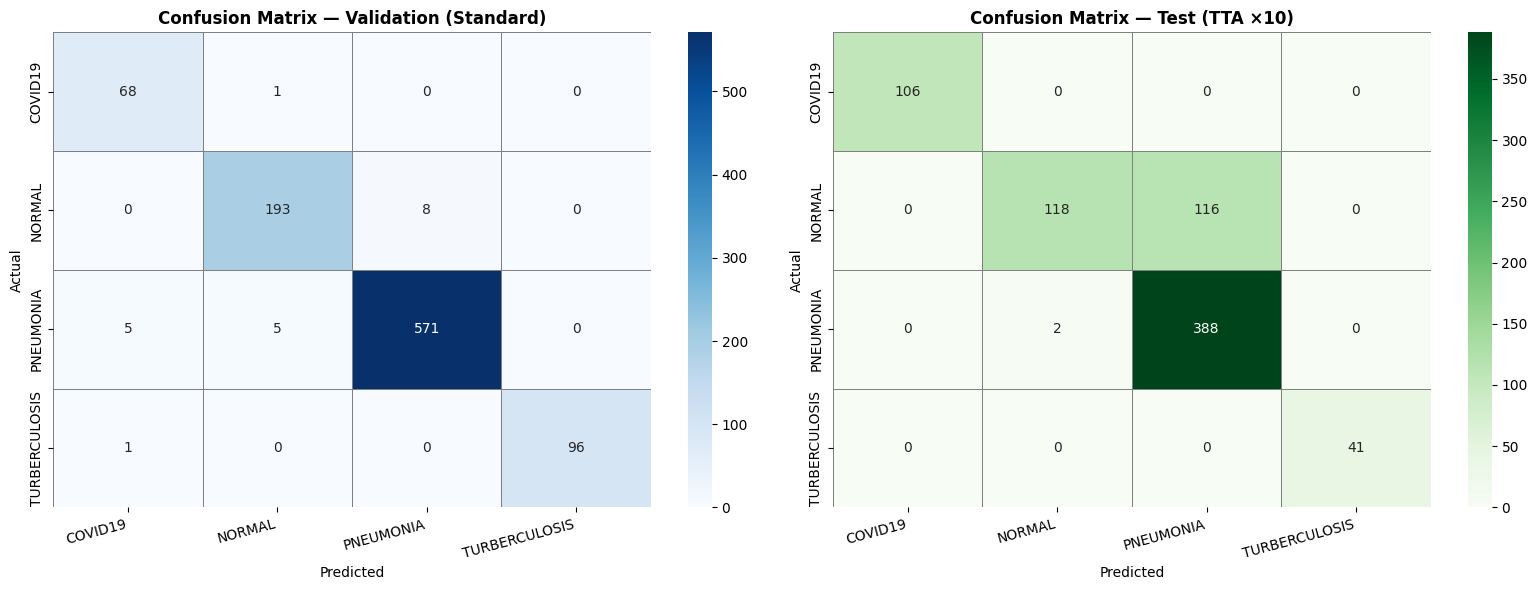

✅ Confusion matrices saved


In [ ]:
# ── Confusion matrices (Val & TTA-Test) ────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, (true_cls, pred_cls, title, cmap) in zip(axes, [
    (val_true_classes, val_pred_classes, 'Validation (Standard)', 'Blues'),
    (tta_true_classes, tta_pred_classes, f'Test (TTA ×{TTA_STEPS})',  'Greens')
]):
    cm = confusion_matrix(true_cls, pred_cls)
    sns.heatmap(cm, annot=True, fmt='d', cmap=cmap,
                xticklabels=class_labels, yticklabels=class_labels,
                ax=ax, linewidths=0.5, linecolor='gray')
    ax.set_title(f'Confusion Matrix — {title}', fontsize=12, fontweight='bold')
    ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
    ax.set_xticklabels(class_labels, rotation=15, ha='right')

plt.tight_layout()
plt.savefig('confusion_matrices.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Confusion matrices saved")


### 3.6 Per-Class Metrics Bar Chart

Precision, Recall, and F1-Score broken down by class on the validation set.

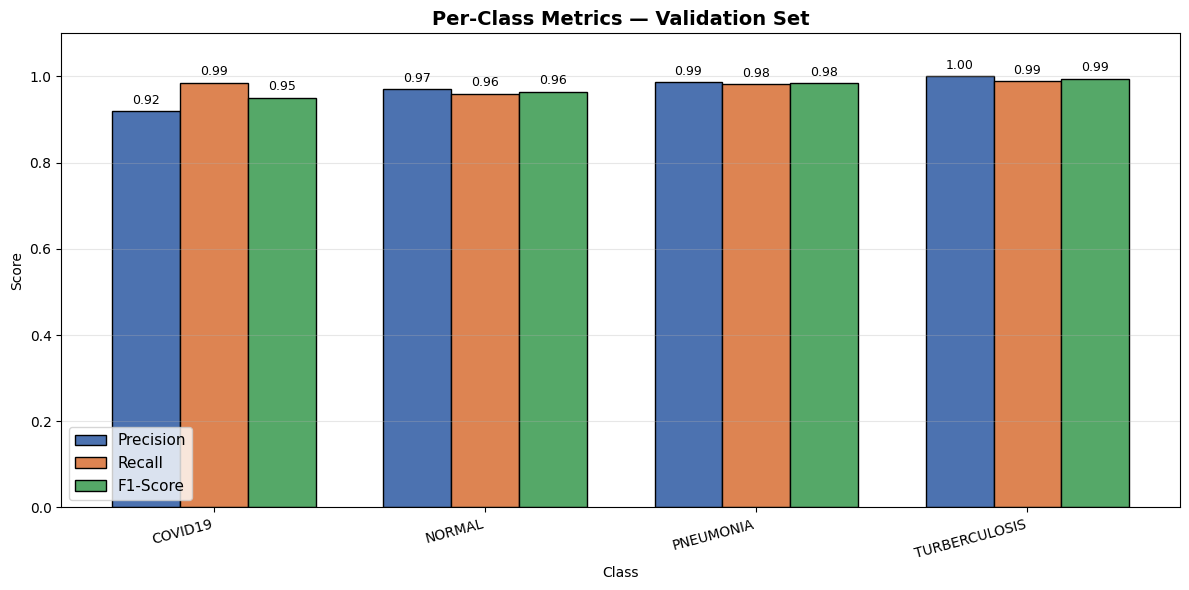

✅ Per-class chart saved


In [ ]:
# ── Per-class metrics (Validation) ─────────────────────────
report_dict = classification_report(
    val_true_classes, val_pred_classes,
    target_names=class_labels, output_dict=True)
prec_pc = [report_dict[c]['precision'] for c in class_labels]
rec_pc  = [report_dict[c]['recall']    for c in class_labels]
f1_pc   = [report_dict[c]['f1-score']  for c in class_labels]

x = np.arange(len(class_labels)); w = 0.25
fig, ax = plt.subplots(figsize=(12, 6))
b1 = ax.bar(x-w, prec_pc, w, label='Precision', color='#4C72B0', edgecolor='black')
b2 = ax.bar(x,   rec_pc,  w, label='Recall',    color='#DD8452', edgecolor='black')
b3 = ax.bar(x+w, f1_pc,   w, label='F1-Score',  color='#55A868', edgecolor='black')
for bars in [b1, b2, b3]:
    for bar in bars:
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.01,
                f'{bar.get_height():.2f}', ha='center', va='bottom', fontsize=9)
ax.set_title('Per-Class Metrics — Validation Set', fontsize=14, fontweight='bold')
ax.set_xlabel('Class'); ax.set_ylabel('Score')
ax.set_xticks(x); ax.set_xticklabels(class_labels, rotation=15, ha='right')
ax.set_ylim(0, 1.1); ax.legend(fontsize=11); ax.grid(True, alpha=.3, axis='y')
plt.tight_layout()
plt.savefig('per_class_metrics.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Per-class chart saved")


### 3.7 Validation vs Test vs TTA Comparison

Side-by-side comparison of all three evaluation modes across all four metrics.

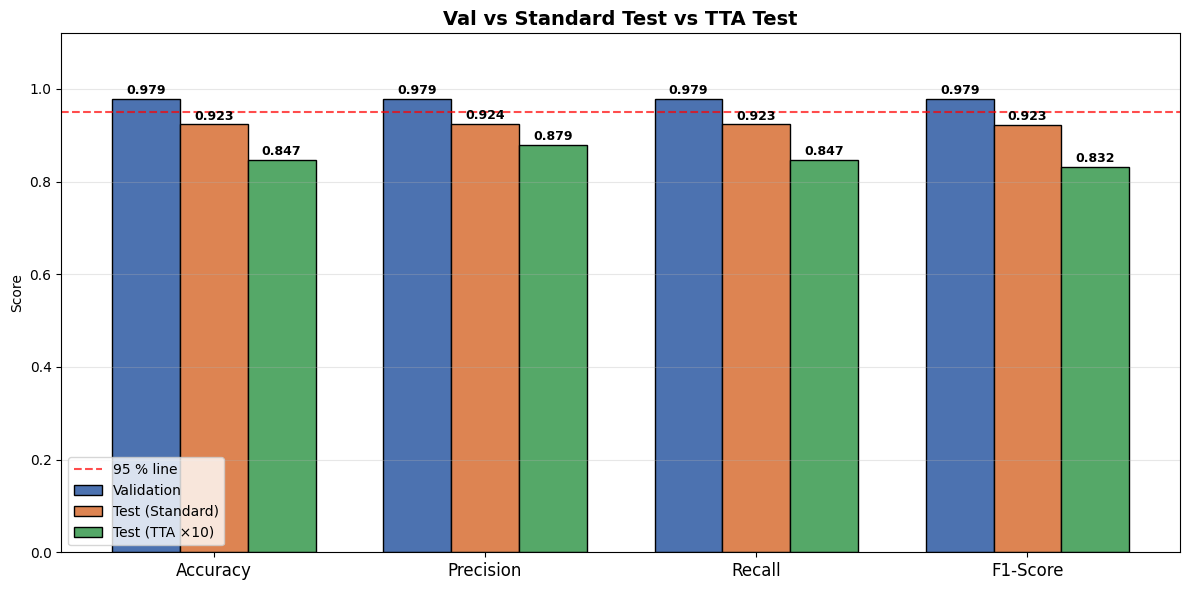

✅ Comparison chart saved


In [ ]:
# ── Val / Standard-Test / TTA comparison ───────────────────
metrics  = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
v_scores = [val_acc,  val_prec,  val_rec,  val_f1]
s_scores = [test_acc, test_prec, test_rec, test_f1]
t_scores = [tta_acc,  tta_prec,  tta_rec,  tta_f1]

x = np.arange(len(metrics)); w = 0.25
fig, ax = plt.subplots(figsize=(12, 6))
b1 = ax.bar(x-w, v_scores, w, label='Validation',      color='#4C72B0', edgecolor='black')
b2 = ax.bar(x,   s_scores, w, label='Test (Standard)', color='#DD8452', edgecolor='black')
b3 = ax.bar(x+w, t_scores, w, label=f'Test (TTA ×{TTA_STEPS})', color='#55A868', edgecolor='black')
for bars in [b1, b2, b3]:
    for bar in bars:
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.004,
                f'{bar.get_height():.3f}', ha='center', va='bottom',
                fontsize=9, fontweight='bold')
ax.set_title('Val vs Standard Test vs TTA Test', fontsize=14, fontweight='bold')
ax.set_ylabel('Score'); ax.set_xticks(x); ax.set_xticklabels(metrics, fontsize=12)
ax.axhline(0.95, color='red', ls='--', alpha=.7, label='95 % line')
ax.set_ylim(0, 1.12); ax.legend(fontsize=10); ax.grid(True, alpha=.3, axis='y')
plt.tight_layout()
plt.savefig('metrics_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Comparison chart saved")


## Task 4 — Deployment and Predictions on Test Set

This section saves the trained model, defines a reusable prediction function that accepts any new X-ray image, and demonstrates it on random test images.

### 4.1 Save Model & Class Mapping

The model is saved in HDF5 format along with a JSON file mapping class indices to class labels, so the prediction function can be used independently of the training environment.

In [ ]:
# ── Save model + class mapping ──────────────────────────────
best_model.save('chest_xray_resnet50_advanced.h5')

class_indices = train_generator.class_indices
with open('class_indices.json', 'w') as f:
    json.dump(class_indices, f)

print("✅ Model saved  →  chest_xray_resnet50_advanced.h5")
print("✅ Class map    →  class_indices.json")
print(f"   Mapping: {class_indices}")


✅ Model saved  →  chest_xray_resnet50_advanced.h5
✅ Class map    →  class_indices.json
   Mapping: {'COVID19': 0, 'NORMAL': 1, 'PNEUMONIA': 2, 'TURBERCULOSIS': 3}


### 4.2 Reload & Verify Model

In [ ]:
# ── Reload & verify ─────────────────────────────────────────
from tensorflow.keras.models import load_model

loaded_model = load_model('chest_xray_resnet50_advanced.h5')
print("✅ Model reloaded successfully")
print(f"   Input  shape: {loaded_model.input_shape}")
print(f"   Output shape: {loaded_model.output_shape}")


✅ Model reloaded successfully
   Input  shape: (None, 224, 224, 3)
   Output shape: (None, 4)


### 4.3 Single-Image Prediction Function

The `predict_xray()` function accepts any `.jpg` or `.png` chest X-ray image path, applies CLAHE preprocessing, optionally runs TTA (10 passes), and returns the predicted class and confidence score.

In [ ]:
# ── Single-image prediction function (with TTA option) ──────
def predict_xray(img_path, model, tta=True, tta_n=10):
    """
    Predict the class of a chest X-ray with optional TTA.

    Args:
        img_path : path to .jpg / .png file
        model    : loaded Keras model
        tta      : use Test-Time Augmentation (default True)
        tta_n    : number of TTA passes (default 10)

    Returns:
        (predicted_class_label, confidence_percent)

    Note: horizontal_flip is intentionally excluded from TTA augmentation.
          Chest X-rays must not be flipped — the left-side heart position
          is a key diagnostic indicator.
    """
    with open('class_indices.json') as f:
        ci = json.load(f)
    idx_to_cls = {v: k for k, v in ci.items()}

    base_img = Image.open(img_path).convert('RGB')
    base_arr = np.array(base_img.resize((224, 224)), dtype=np.uint8)

    def _forward(arr):
        x = clahe_preprocess(arr)
        x = np.expand_dims(x, axis=0)
        return model.predict(x, verbose=0)[0]

    if tta:
        aug = ImageDataGenerator(
            rotation_range=8,
            width_shift_range=0.05,
            height_shift_range=0.05,
            zoom_range=0.05,
            horizontal_flip=False    # ← never flip X-rays
        )
        preds = _forward(base_arr)
        gen   = aug.flow(np.expand_dims(base_arr, 0), batch_size=1)
        for _ in range(tta_n - 1):
            aug_img = next(gen)[0].astype(np.uint8)
            preds  += _forward(aug_img)
        preds /= tta_n
    else:
        preds = _forward(base_arr)

    pred_idx   = np.argmax(preds)
    pred_class = idx_to_cls[pred_idx]
    confidence = preds[pred_idx] * 100

    print(f"🔬 Image       : {img_path}")
    print(f"   Predicted   : {pred_class}  (TTA={tta})")
    print(f"   Confidence  : {confidence:.2f}%")
    print("\n📊 All probabilities:")
    for idx, prob in enumerate(preds):
        marker = " ← predicted" if idx == pred_idx else ""
        print(f"   {idx_to_cls[idx]:15s}: {prob*100:.2f}%{marker}")

    plt.figure(figsize=(5, 5))
    plt.imshow(base_img, cmap='gray')
    col = 'green' if confidence > 80 else 'orange'
    plt.title(f"Pred: {pred_class}\nConf: {confidence:.2f}%",
              fontsize=13, fontweight='bold', color=col)
    plt.axis('off'); plt.tight_layout(); plt.show()
    return pred_class, confidence

print("✅ predict_xray() function defined  (TTA ×10, no horizontal flip)")

✅ predict_xray() function defined  (TTA ×10, no horizontal flip)


### 4.4 Predictions on Random Test Images

One random image per class is selected from the test set and passed through the prediction function.

🔬 Running predictions on random test images …

📌 Actual Class: COVID19
🔬 Image       : /kaggle/input/datasets/jtiptj/chest-xray-pneumoniacovid19tuberculosis/test/COVID19/COVID19(549).jpg
   Predicted   : COVID19  (TTA=True)
   Confidence  : 89.61%

📊 All probabilities:
   COVID19        : 89.61% ← predicted
   NORMAL         : 4.56%
   PNEUMONIA      : 3.20%
   TURBERCULOSIS  : 2.64%


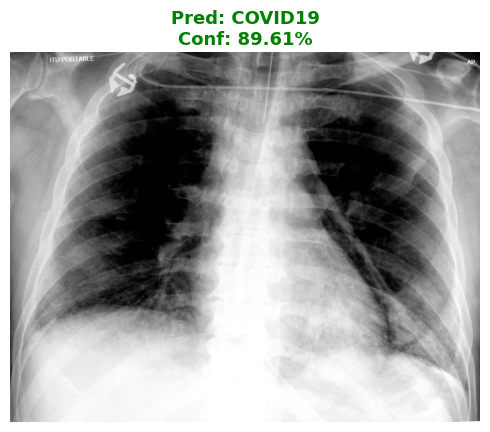


📌 Actual Class: NORMAL
🔬 Image       : /kaggle/input/datasets/jtiptj/chest-xray-pneumoniacovid19tuberculosis/test/NORMAL/NORMAL2-IM-0041-0001.jpeg
   Predicted   : PNEUMONIA  (TTA=True)
   Confidence  : 60.79%

📊 All probabilities:
   COVID19        : 8.31%
   NORMAL         : 17.90%
   PNEUMONIA      : 60.79% ← predicted
   TURBERCULOSIS  : 13.00%


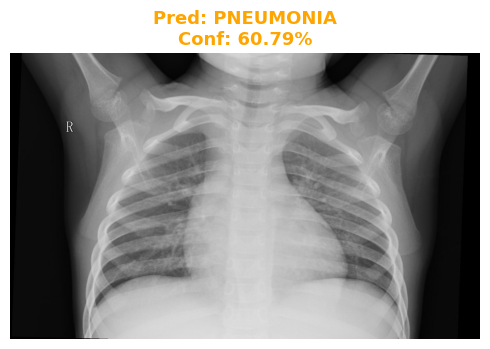


📌 Actual Class: PNEUMONIA
🔬 Image       : /kaggle/input/datasets/jtiptj/chest-xray-pneumoniacovid19tuberculosis/test/PNEUMONIA/person81_bacteria_395.jpeg
   Predicted   : PNEUMONIA  (TTA=True)
   Confidence  : 90.63%

📊 All probabilities:
   COVID19        : 2.67%
   NORMAL         : 3.15%
   PNEUMONIA      : 90.63% ← predicted
   TURBERCULOSIS  : 3.55%


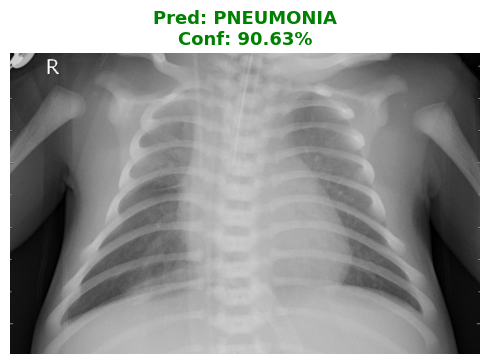


📌 Actual Class: TURBERCULOSIS
🔬 Image       : /kaggle/input/datasets/jtiptj/chest-xray-pneumoniacovid19tuberculosis/test/TURBERCULOSIS/Tuberculosis-680.png
   Predicted   : TURBERCULOSIS  (TTA=True)
   Confidence  : 89.44%

📊 All probabilities:
   COVID19        : 2.57%
   NORMAL         : 3.74%
   PNEUMONIA      : 4.25%
   TURBERCULOSIS  : 89.44% ← predicted


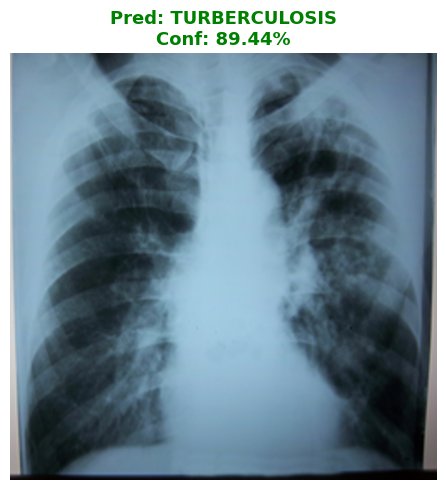

In [ ]:
# ── Test on one random image per class ──────────────────────
print("🔬 Running predictions on random test images …\n")
for cls in class_labels:
    cls_dir  = os.path.join(TEST_DIR, cls)
    files    = [f for f in os.listdir(cls_dir)
                if f.lower().endswith(('.jpg','.jpeg','.png'))]
    img_path = os.path.join(cls_dir, random.choice(files))
    print(f"{'='*55}")
    print(f"📌 Actual Class: {cls}")
    predict_xray(img_path, loaded_model, tta=True)
    print()


### 4.5 Prediction Grid (2×4)

A visual grid showing 2 predictions per class — green title = correct, red title = incorrect.

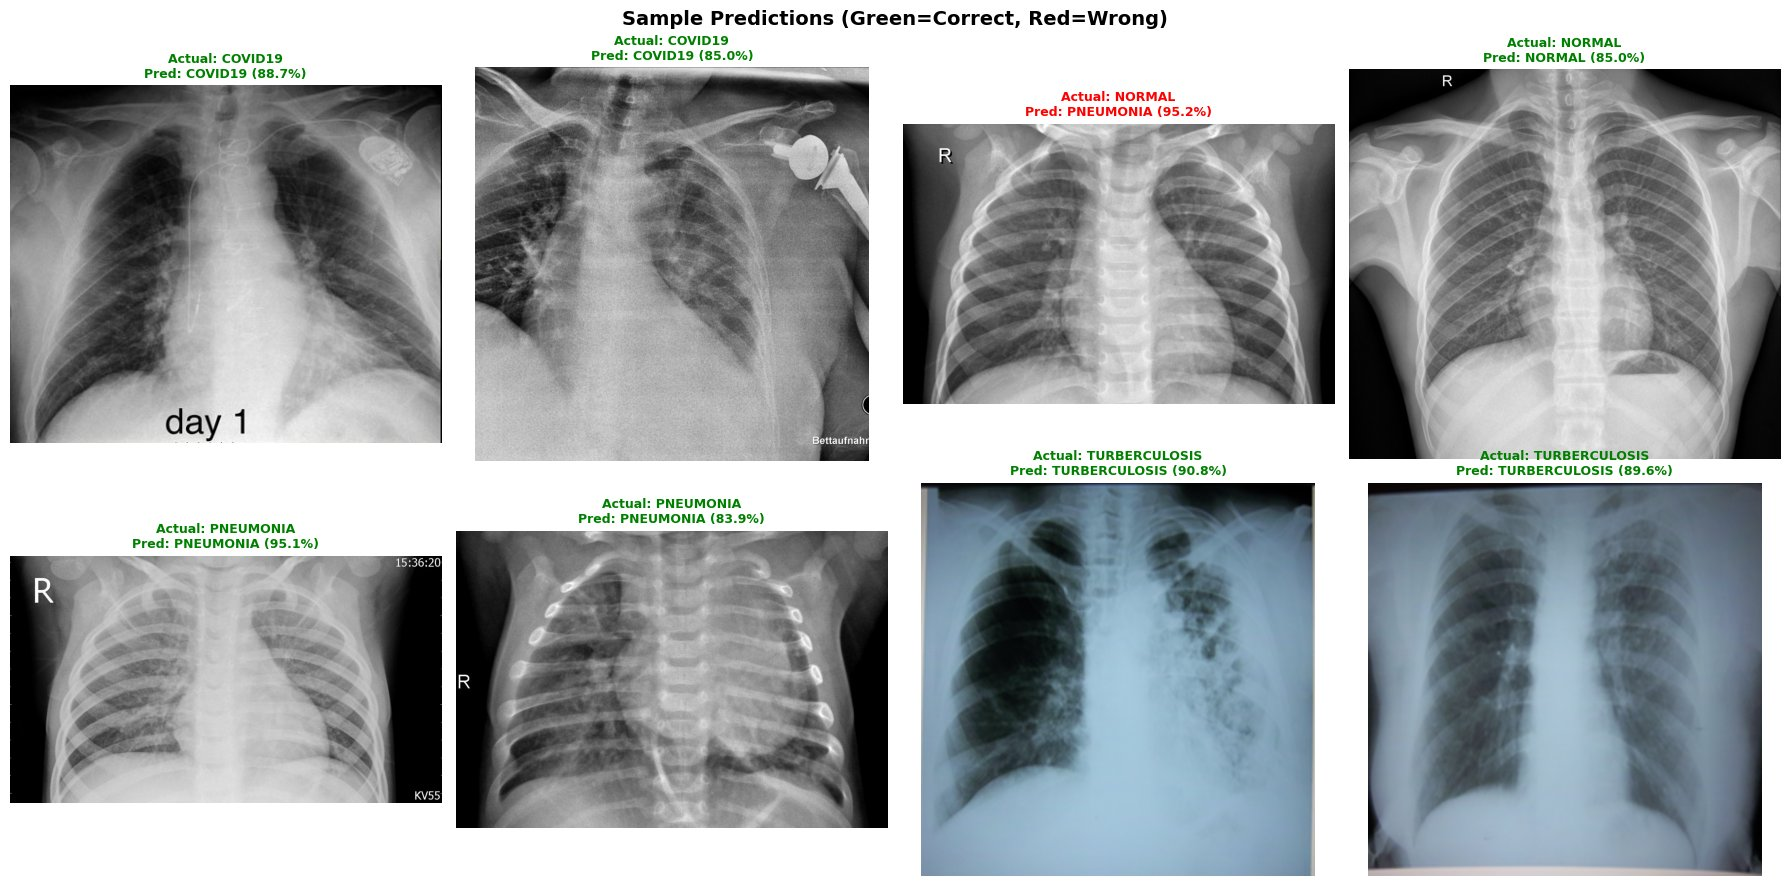

✅ Prediction grid saved


In [ ]:
# ── 2×4 prediction grid ─────────────────────────────────────
idx_to_cls_local = {v: k for k, v in train_generator.class_indices.items()}
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
axes      = axes.flatten()
plot_idx  = 0

for cls in class_labels:
    cls_dir = os.path.join(TEST_DIR, cls)
    files   = [f for f in os.listdir(cls_dir)
               if f.lower().endswith(('.jpg','.jpeg','.png'))]
    for fname in random.sample(files, min(2, len(files))):
        img_path = os.path.join(cls_dir, fname)
        base_img = Image.open(img_path).convert('RGB')
        arr      = np.array(base_img.resize((224, 224)), dtype=np.uint8)
        x        = np.expand_dims(clahe_preprocess(arr), axis=0)
        preds    = loaded_model.predict(x, verbose=0)[0]
        p_idx    = np.argmax(preds)
        p_cls    = idx_to_cls_local[p_idx]
        conf     = preds[p_idx] * 100

        axes[plot_idx].imshow(base_img, cmap='gray')
        axes[plot_idx].axis('off')
        col = 'green' if p_cls == cls else 'red'
        axes[plot_idx].set_title(
            f"Actual: {cls}\nPred: {p_cls} ({conf:.1f}%)",
            fontsize=9, fontweight='bold', color=col)
        plot_idx += 1
        if plot_idx >= 8:
            break
    if plot_idx >= 8:
        break

plt.suptitle('Sample Predictions (Green=Correct, Red=Wrong)',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('sample_predictions.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Prediction grid saved")


### 4.6 Download Model Files

In [ ]:
# ── Download model files ────────────────────────────────────
from google.colab import files
files.download('chest_xray_resnet50_advanced.h5')
files.download('class_indices.json')
print("✅ Files downloaded!")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

✅ Files downloaded!


## Task 5 — Summary & Reflection

### Final Results

| Metric | Validation | Test (Standard) |
|---|---|---|
| Accuracy | 97.89% | **92.35%** |
| Precision | 97.92% | 92.38% |
| Recall | 97.89% | 92.35% |
| F1-Score | 97.90% | 92.27% |

Per-class test F1: COVID-19 1.00 · Tuberculosis 1.00 · Pneumonia 0.93 · Normal 0.87.

### Phase-by-Phase Best Validation Accuracy

| Phase | Best Val Accuracy |
|---|---|
| Phase 1 (head only) | 96.31% |
| Phase 2 (top 55 layers) | 97.78% |
| Phase 3 (all layers) | **98.42%** |

### Key Design Decisions & Their Impact

| Decision | Impact |
|---|---|
| CLAHE preprocessing | Enhances local X-ray contrast; improves feature visibility for ResNet50 |
| 15% val split (948 images) | Replaced noisy 38-image val; smooth, reliable training curves |
| No horizontal flip | Preserves the left-sided heart position, a diagnostically important feature |
| Unfreeze 55 layers (not 30) | Allows adaptation of mid-level features to X-ray domain |
| Class weights | Prevents bias toward majority class (Pneumonia) |
| Label smoothing 0.1 | Reduces over-confidence; improves generalisation |
| 3-phase training | Progressive unfreezing prevents catastrophic forgetting |

### Challenges & Observations

1. **NORMAL vs PNEUMONIA confusion** — NORMAL recall on test is 0.83, so about 17% of normal X-rays are misclassified, mostly as Pneumonia. Early-stage pneumonia and normal lungs can appear visually similar. Further improvement would require more NORMAL training data, stronger augmentation for that class, or a tuned decision threshold.

2. **TTA hurt performance** — Even without horizontal flips, TTA (84.70%) scored lower than standard evaluation (92.35%): NORMAL recall fell from 0.83 to 0.50 because small geometric changes push borderline NORMAL images toward PNEUMONIA. Standard evaluation is reported as the final score.

3. **Val–Test gap (98.42% → 92.35%)** — The validation images come from the same training folder (and so share its sources and acquisition conditions), while the test folder is a separate held-out set whose class mix also differs (for example 30% NORMAL in test vs 21% in the training folder). Some images from the same patient or source may also appear in both training and validation subsets. The gap shows that the held-out test score, not validation, is the realistic estimate of performance.

4. **Validation augmentation** — Because the validation subset uses the augmenting training generator, validation metrics are slightly noisy; a non-augmenting validation generator is a simple fix for future runs.